# Nhiệm vụ 9 — Temporal Stability PCA + K-Means V2

Đánh giá đúng 59 cặp development liên tiếp trong 60 tháng 2019-01-31–2023-12-29.
Đây là temporal stability diagnostic của các mô hình fit độc lập từng tháng,
không phải thuật toán Dynamic Clustering. Không fit model, không tính lại ARI/NMI,
không gọi backend temporal/runner và không mở holdout 2024–2025.

**Cách chạy:** chọn kernel Python 3.11 trở lên, Restart Kernel rồi Run All.
Notebook có bốn bảng chuẩn, hai biểu đồ và kết luận A/B/C. Chạy tới thông báo
PASS nhiệm vụ 9 để hoàn tất xuất kết quả.

**Bước chuẩn bị định dạng:** Task 6 V2 hiện lưu stability.jsonl và transitions.csv,
chưa có ba CSV phẳng. Notebook chuyển các kết quả có sẵn sang schema chuẩn,
đối chiếu nhãn aligned và các điểm đầu/cuối của drift với profile đã đóng băng.
Sau bước này, tầng phân tích chỉ đọc temporal_stability.csv, transition_matrices.csv
và centroid_drift.csv. Không dùng nhãn raw/pair-local trong JSONL để đặt tên cụm xuyên chuỗi.

Kết quả mới được ghi trong m2-evaluation-pca-kmeans-v2; bộ legacy 15 tháng giữ nguyên.
Rerun cùng nội dung chỉ kiểm chứng/tái sử dụng; nội dung khác cần phiên bản mới.


In [1]:
from pathlib import Path
from io import BytesIO
from collections import Counter
import hashlib
import json
import math
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

CWD = Path.cwd().resolve()
ROOT = next((p for p in [CWD, *CWD.parents]
             if (p / 'configs/experiments/m2_market_only_v2.json').is_file()), None)
if ROOT is None:
    ROOT = next((p for p in CWD.iterdir()
                 if p.is_dir() and (p / 'configs/experiments/m2_market_only_v2.json').is_file()), None)
if ROOT is None:
    raise FileNotFoundError('Mở workspace M2_v1, repository hoặc M2/notebooks.')
TASK_DIR = ROOT / 'M2/artifacts/m2-task6-pca-kmeans-v2'
EVAL_DIR = ROOT / 'M2/artifacts/m2-evaluation-pca-kmeans-v2'
REPORT_PATH = ROOT / 'M2/reports/Bao_cao_M2_Nhiem_vu_9_Do_on_dinh_thoi_gian_PCA_KMeans_v2.md'
EXPECTED_SOURCE_HASHES = {'stability.jsonl': '3cabb206ced10d96819647e6fe24f5122d438c6c375e9d77397e413c6608a3dc', 'transitions.csv': '67ecd2ea6681be663306bf398b0b5ed1a0c02a67e9d988b64a38d202d9656984', 'assignments.csv': '79b7c63223fba8273c4178068baaf2b682583abc50f3310f80165ae1a6d63486', 'cluster_profiles.csv': '9dd6b3528faeee871ba63d8168d45661dc706bd51f61f960422243b340d8e564'}
TEMP_COLUMNS = ['from_date','to_date','n_common','ari','nmi','persistence_probability',
                'migration_rate','entered_count','exited_count','status']
TRANSITION_COLUMNS = ['from_date','to_date','from_cluster','to_cluster','count','rate']
DRIFT_COLUMNS = ['from_date','to_date','aligned_cluster_id','feature','value_from','value_to','delta']

def sha(path):
    return hashlib.sha256(Path(path).read_bytes()).hexdigest()

def immutable_bytes(path, content):
    path = Path(path)
    path.parent.mkdir(parents=True, exist_ok=True)
    if path.exists():
        if path.read_bytes() != content:
            raise FileExistsError(f'Nội dung khác đã tồn tại: {path}; cần version mới.')
    else:
        with path.open('xb') as stream:
            stream.write(content)

def json_bytes(data):
    return (json.dumps(data, ensure_ascii=False, indent=2, allow_nan=False) + '\n').encode('utf-8')

def markdown_table(frame):
    def clean(value):
        return str(value).replace('|', r'\|').replace('\n', ' ')
    return '\n'.join(
        ['| ' + ' | '.join(map(clean, frame.columns)) + ' |',
         '| ' + ' | '.join(['---'] * len(frame.columns)) + ' |']
        + ['| ' + ' | '.join(map(clean, row)) + ' |' for row in frame.itertuples(index=False, name=None)])

SOURCE_MANIFEST_PATH = TASK_DIR / 'manifest.json'
SOURCE_MANIFEST_HASH = sha(SOURCE_MANIFEST_PATH)
source_manifest = json.loads(SOURCE_MANIFEST_PATH.read_text(encoding='utf-8'))
assert source_manifest['status'] == 'complete' and source_manifest['task6_exports_complete'] is True
assert source_manifest['artifact_id'] == 'm2-task6-pca-kmeans-v2'
CONFIG = source_manifest['config']
DEV_DATES = CONFIG['development_snapshots']
FEATURES = CONFIG['clustering']['features']
assert CONFIG['protocol_scope'] == 'm2_market_only_v2' and CONFIG['clustering']['k'] == 2
assert CONFIG['clustering']['algorithm'] == 'pca_kmeans' and CONFIG['portfolio_evaluation']['enabled'] is False
assert len(DEV_DATES) == 60 and len(FEATURES) == 8
assert DEV_DATES[0] == '2019-01-31' and DEV_DATES[-1] == '2023-12-29'
month_numbers = [int(day[:4]) * 12 + int(day[5:7]) for day in DEV_DATES]
assert all(b - a == 1 for a, b in zip(month_numbers, month_numbers[1:])), 'Gap: không nối chuỗi qua tháng thiếu.'
EXPECTED_PAIRS = list(zip(DEV_DATES, DEV_DATES[1:]))
for relative, expected in EXPECTED_SOURCE_HASHES.items():
    assert sha(TASK_DIR / relative) == expected == source_manifest['artifacts'][relative]
print('Nguồn:', TASK_DIR)
print('PASS: 60 tháng development liên tục; 59 cặp; không nối sang holdout 2024–2025.')


Nguồn: C:\Users\HOME\Desktop\M2_v1\Risk-Adjusted-Momentum-Clustering-m2-clustering-experiment\M2\artifacts\m2-task6-pca-kmeans-v2
PASS: 60 tháng development liên tục; 59 cặp; không nối sang holdout 2024–2025.


## Bước 0 — Chuẩn bị ba CSV phẳng, không tính lại mô hình

ARI/NMI/Persistence/Migration được sao chép từ stability.jsonl đã đóng băng.
Transition dùng from_cluster/to_cluster aligned trong transitions.csv.
Drift lấy value_from/value_to của cùng aligned_cluster_id trong profile gốc;
đối chiếu thêm delta và mapping raw đã lưu để phát hiện nhầm nhãn.
Assignments chỉ dùng kiểm chứng giao universe và số lượt chuyển cụm, không căn chỉnh nhãn lại.


In [2]:
stability_rows = [json.loads(line) for line in (TASK_DIR/'stability.jsonl').read_text(encoding='utf-8').splitlines() if line.strip()]
transitions_source = pd.read_csv(TASK_DIR/'transitions.csv')
assignments_source = pd.read_csv(TASK_DIR/'assignments.csv')
profiles_source = pd.read_csv(TASK_DIR/'cluster_profiles.csv')
assert [(r['from_date'],r['to_date']) for r in stability_rows] == EXPECTED_PAIRS
assert not assignments_source.duplicated(['snapshot_date','security_id']).any()
assert sorted(assignments_source.snapshot_date.unique()) == DEV_DATES
assert len(assignments_source) == source_manifest['n_assignments']
assert len(profiles_source) == 120
assert not profiles_source.duplicated(['snapshot_date','aligned_cluster_id']).any()
membership = {
    day:dict(zip(frame.security_id,frame.aligned_cluster_id.astype(int)))
    for day,frame in assignments_source.groupby('snapshot_date')
}
profiles_aligned = profiles_source.set_index(['snapshot_date','aligned_cluster_id'])
profiles_raw = profiles_source.set_index(['snapshot_date','raw_cluster_id'])
temp_records, drift_records = [], []
for record in stability_rows:
    before,after = record['from_date'],record['to_date']
    a,b = membership[before],membership[after]
    shared = set(a) & set(b)
    assert record['n_common'] == len(shared) and len(shared) >= 2
    assert set(record['entered']) == set(b)-set(a)
    assert set(record['exited']) == set(a)-set(b)
    assert all(math.isfinite(record[k]) for k in ['ari','nmi','persistence_probability','migration_rate'])
    pair = transitions_source[transitions_source.from_date.eq(before) & transitions_source.to_date.eq(after)]
    assert len(pair) == 4
    assert set(zip(pair.from_cluster,pair.to_cluster)) == {(0,0),(0,1),(1,0),(1,1)}
    observed = Counter((a[s],b[s]) for s in shared)
    denominators = Counter(a[s] for s in shared)
    for t in pair.itertuples(index=False):
        assert t.count == observed[(t.from_cluster,t.to_cluster)]
        assert t.denominator == denominators[t.from_cluster] > 0
        assert math.isclose(t.rate,t.count/t.denominator,abs_tol=1e-12,rel_tol=1e-12)
    persistence = sum(a[s] == b[s] for s in shared)/len(shared)
    assert math.isclose(record['persistence_probability'],persistence,abs_tol=1e-12)
    assert math.isclose(record['migration_rate'],1-persistence,abs_tol=1e-12)
    temp_records.append(dict(
        from_date=before,to_date=after,n_common=len(shared),
        ari=record['ari'],nmi=record['nmi'],
        persistence_probability=record['persistence_probability'],migration_rate=record['migration_rate'],
        entered_count=len(record['entered']),exited_count=len(record['exited']),status='OK'))
    for aligned_id in [0,1]:
        prior = profiles_aligned.loc[(before,aligned_id)]
        current = profiles_aligned.loc[(after,aligned_id)]
        raw_current = int(current.raw_cluster_id)
        raw_prior = int(record['mapping'][str(raw_current)])
        assert int(profiles_raw.loc[(before,raw_prior),'aligned_cluster_id']) == aligned_id
        for feature in FEATURES:
            value_from,value_to = float(prior[feature]),float(current[feature])
            delta = value_to-value_from
            recorded_delta = record['centroid_drift'][str(raw_current)][feature]
            tolerance = 1e-12*max(abs(value_from),abs(value_to),1)
            assert math.isclose(delta,recorded_delta,rel_tol=1e-9,abs_tol=tolerance)
            drift_records.append(dict(from_date=before,to_date=after,aligned_cluster_id=aligned_id,
                feature=feature,value_from=value_from,value_to=value_to,delta=delta))
df_temp_prepared = pd.DataFrame(temp_records,columns=TEMP_COLUMNS)
df_transition_prepared = transitions_source[TRANSITION_COLUMNS].sort_values(
    ['from_date','to_date','from_cluster','to_cluster']).reset_index(drop=True)
df_drift_prepared = pd.DataFrame(drift_records,columns=DRIFT_COLUMNS)
assert df_temp_prepared.shape == (59,10)
assert df_transition_prepared.shape == (236,6) and df_drift_prepared.shape == (944,7)
PREPARED_FRAMES = {
    'temporal_stability.csv':df_temp_prepared,
    'transition_matrices.csv':df_transition_prepared,
    'centroid_drift.csv':df_drift_prepared,
}
print('PASS: định dạng 59×10, 236×6, 944×7; transition khớp assignments; drift cùng nhãn aligned.')


PASS: định dạng 59×10, 236×6, 944×7; transition khớp assignments; drift cùng nhãn aligned.


In [3]:
# Cell đầu tiên ghi file: chỉ chuẩn hóa artifact đã có, không gọi backend.
for name,frame in PREPARED_FRAMES.items():
    immutable_bytes(EVAL_DIR/name,frame.to_csv(index=False,lineterminator='\n').encode('utf-8'))
input_hashes = {name:sha(EVAL_DIR/name) for name in PREPARED_FRAMES}
inputs_manifest = dict(
    artifact_id='m2-task9-pca-kmeans-inputs-v2',status='complete',
    source_artifact_id=source_manifest['artifact_id'],source_manifest_sha256=SOURCE_MANIFEST_HASH,
    source_artifacts_sha256=EXPECTED_SOURCE_HASHES,outputs=input_hashes,
    ari_nmi_recomputed=False,label_matching_recomputed=False,model_refitted=False,
    drift_basis='saved_original_feature_profiles_with_global_aligned_ids',
)
immutable_bytes(EVAL_DIR/'task9_inputs_manifest.json',json_bytes(inputs_manifest))
print('Đã chuẩn bị ba CSV phẳng; tiếp tục phần phân tích bên dưới.')


Đã chuẩn bị ba CSV phẳng; tiếp tục phần phân tích bên dưới.


## Bước 1 — Đọc ba CSV chuẩn và kiểm tra reset gap

Từ đây mọi bảng/biểu đồ chỉ dùng ba CSV phẳng.
Không nối cặp qua gap, không tạo cặp 2023-12 → 2024-01.
Tỷ lệ transition là xác suất có điều kiện theo cụm nguồn trên tập mã chung;
không cộng hoặc lấy trung bình đơn giản các rate tháng để thay cho tỷ lệ tích lũy.


In [4]:
df_temp = pd.read_csv(EVAL_DIR/'temporal_stability.csv')
df_transition = pd.read_csv(EVAL_DIR/'transition_matrices.csv')
df_drift = pd.read_csv(EVAL_DIR/'centroid_drift.csv')
assert df_temp.columns.tolist() == TEMP_COLUMNS and df_temp.shape == (59,10)
assert df_transition.columns.tolist() == TRANSITION_COLUMNS and df_transition.shape == (236,6)
assert df_drift.columns.tolist() == DRIFT_COLUMNS and df_drift.shape == (944,7)
assert list(zip(df_temp.from_date,df_temp.to_date)) == EXPECTED_PAIRS
assert set(zip(df_transition.from_date,df_transition.to_date)) == set(EXPECTED_PAIRS)
assert set(zip(df_drift.from_date,df_drift.to_date)) == set(EXPECTED_PAIRS)
assert not df_transition.duplicated(['from_date','to_date','from_cluster','to_cluster']).any()
assert not df_drift.duplicated(['from_date','to_date','aligned_cluster_id','feature']).any()
assert df_temp.status.eq('OK').all() and df_temp.n_common.ge(2).all()
assert np.isfinite(df_temp[['ari','nmi','persistence_probability','migration_rate']]).all().all()
assert df_temp.ari.between(-1-1e-12,1+1e-12).all() and df_temp.nmi.between(-1e-12,1+1e-12).all()  # Numerical boundary tolerance; no data clipping.
assert df_temp.persistence_probability.between(0,1).all() and df_temp.migration_rate.between(0,1).all()
assert np.allclose(df_temp.persistence_probability+df_temp.migration_rate,1)
assert np.isfinite(df_drift[['value_from','value_to','delta']]).all().all()
assert np.allclose(df_drift.value_to-df_drift.value_from,df_drift.delta,rtol=1e-9,atol=1e-9)
assert df_drift.groupby(['from_date','to_date']).size().eq(16).all()
for pair in EXPECTED_PAIRS:
    part = df_transition[df_transition.from_date.eq(pair[0]) & df_transition.to_date.eq(pair[1])]
    assert len(part)==4 and part['count'].ge(0).all() and part['count'].mod(1).eq(0).all()
    common = int(df_temp.loc[df_temp.from_date.eq(pair[0]),'n_common'].iloc[0])
    assert int(part['count'].sum()) == common
    for cluster in [0,1]:
        row = part[part.from_cluster.eq(cluster)]
        assert row['count'].sum()>0
        assert np.allclose(row.rate,row['count']/row['count'].sum(),rtol=1e-12,atol=1e-12)
print('PASS Reset Gap: đúng 59 cặp tháng liên tiếp, development đóng kín 2019–2023.')


PASS Reset Gap: đúng 59 cặp tháng liên tiếp, development đóng kín 2019–2023.


## Bước 2 — Bốn bảng chuẩn

1. ARI/NMI/Persistence/Migration: 4×6; hai tỷ lệ thành viên đổi sang %.
2. Transition tích lũy: 4×5; rate=tổng count / tổng cơ sở cụm nguồn.
3. Mean |Delta| theo feature: 8×3; thanh khoản chia 10^9, các feature khác giữ đơn vị gốc.
4. Entry/Exit: 59×5; tỷ lệ luân chuyển universe=(Entry+Exit)/n_common×100.

Tỷ lệ universe có thể vượt 100%; không phải migration và không phải portfolio turnover.
Drift còn chịu ảnh hưởng thay đổi thành viên, không chỉ biến động giá của một cohort cố định.


In [5]:
rows = []
for metric,label,multiplier in [
    ('ari','ARI',1),('nmi','NMI',1),
    ('persistence_probability','Persistence (%)',100),('migration_rate','Migration (%)',100)]:
    values = df_temp[metric]*multiplier
    rows.append({
        'Chỉ số (Metric)':label,'Số cặp quan sát':len(values),
        'Trung bình (Mean)':values.mean(),'Trung vị (Median)':values.median(),
        'Nhỏ nhất (Min)':values.min(),'Lớn nhất (Max)':values.max()})
table1 = pd.DataFrame(rows)
counts = df_transition.groupby(['from_cluster','to_cluster'])['count'].sum().unstack().reindex(index=[0,1],columns=[0,1])
assert counts.notna().all().all()
denominators = counts.sum(axis=1)
assert denominators.gt(0).all()
transition_rates = counts.div(denominators,axis=0)*100
table2 = pd.DataFrame([{
    'Từ Cụm (From)':f'Cụm {a}',
    'Sang Cụm (To)':f'Cụm {b} ('+('Giữ nguyên' if a==b else 'Chuyển cụm')+')',
    'Tổng số lượt (Count)':int(counts.loc[a,b]),
    'Tổng số cơ sở (Denominator)':int(denominators.loc[a]),
    'Tỷ lệ xác suất (Rate %)':float(transition_rates.loc[a,b]),
} for a,b in [(0,0),(0,1),(1,1),(1,0)]])
FEATURE_ORDER = ['liquidity_21','beta_126','vol_63','mdd_126','mom_21','mom_63','mom_126','mom_252']
drift_means = df_drift.assign(abs_delta=df_drift.delta.abs()).groupby(
    ['feature','aligned_cluster_id']).abs_delta.mean().unstack()
table3 = pd.DataFrame([{
    'Đặc trưng':feature+(' (tỷ VND)' if feature=='liquidity_21' else ''),
    'Độ lệch tuyệt đối Cụm 0 (Mean |Delta|)':drift_means.loc[feature,0]/(1e9 if feature=='liquidity_21' else 1),
    'Độ lệch tuyệt đối Cụm 1 (Mean |Delta|)':drift_means.loc[feature,1]/(1e9 if feature=='liquidity_21' else 1),
} for feature in FEATURE_ORDER])
universe_ratio = (df_temp.entered_count+df_temp.exited_count)/df_temp.n_common*100
table4 = pd.DataFrame({
    'Cặp Snapshot (From -> To)':[f'{a[:7]} → {b[:7]}' for a,b in EXPECTED_PAIRS],
    'Số mã chung (n_common)':df_temp.n_common,'Số mã mới (Entry)':df_temp.entered_count,
    'Số mã rớt (Exit)':df_temp.exited_count,'Tỷ lệ luân chuyển (%)':universe_ratio,
})
assert table1.shape==(4,6) and table2.shape==(4,5) and table3.shape==(8,3) and table4.shape==(59,5)
with pd.option_context('display.max_rows',60,'display.max_columns',6):
    for number,frame in enumerate([table1,table2,table3,table4],1):
        display(Markdown(f'### Bảng {number}'))
        display(frame.round(6))


### Bảng 1

,Chỉ số (Metric),Số cặp quan sát,Trung bình (Mean),Trung vị (Median),Nhỏ nhất (Min),Lớn nhất (Max)
0,ARI,59,0.747575,0.743427,0.230167,1.000000
1,NMI,59,0.636082,0.592307,0.182405,1.000000
2,Persistence (%),59,98.640468,98.827471,95.614035,100.000000
3,Migration (%),59,1.359532,1.172529,0.000000,4.385965


### Bảng 2

,Từ Cụm (From),Sang Cụm (To),Tổng số lượt (Count),Tổng số cơ sở (Denominator),Tỷ lệ xác suất (Rate %)
0,Cụm 0,Cụm 0 (Giữ nguyên),498,670,74.328358
1,Cụm 0,Cụm 1 (Chuyển cụm),172,670,25.671642
2,Cụm 1,Cụm 1 (Giữ nguyên),26492,26669,99.336308
3,Cụm 1,Cụm 0 (Chuyển cụm),177,26669,0.663692


### Bảng 3

,Đặc trưng,Độ lệch tuyệt đối Cụm 0 (Mean |Delta|),Độ lệch tuyệt đối Cụm 1 (Mean |Delta|)
0,liquidity_21 (tỷ VND),73.555190,1.635837
1,beta_126,0.150382,0.037246
2,vol_63,0.076999,0.026047
3,mdd_126,0.043221,0.014494
4,mom_21,0.111403,0.049092
5,mom_63,0.232845,0.058394
6,mom_126,0.335038,0.059247
7,mom_252,0.396687,0.080186


### Bảng 4

,Cặp Snapshot (From -> To),Số mã chung (n_common),Số mã mới (Entry),Số mã rớt (Exit),Tỷ lệ luân chuyển (%)
0,2019-01 → 2019-02,655,1,1,0.305344
1,2019-02 → 2019-03,656,6,0,0.914634
2,2019-03 → 2019-04,660,9,2,1.666667
3,2019-04 → 2019-05,661,19,8,4.084720
4,2019-05 → 2019-06,676,19,4,3.402367
5,2019-06 → 2019-07,693,13,2,2.164502
6,2019-07 → 2019-08,705,56,1,8.085106
7,2019-08 → 2019-09,761,20,0,2.628121
8,2019-09 → 2019-10,746,25,35,8.042895
9,2019-10 → 2019-11,764,9,7,2.094241


## Bước 3 — Hai biểu đồ chuẩn

Biểu đồ đa panel 12×8 inch hiển thị đủ 59 cặp, có trung vị ARI/NMI và
Persistence/Migration. Trên dữ liệu hiện tại ARI dương nên trục trên là 0–1;
nếu có ARI âm sẽ mở rộng trục để không che quan sát.
Heatmap Blues 2×2 trình bày phần trăm có điều kiện theo hàng, không theo toàn ma trận.


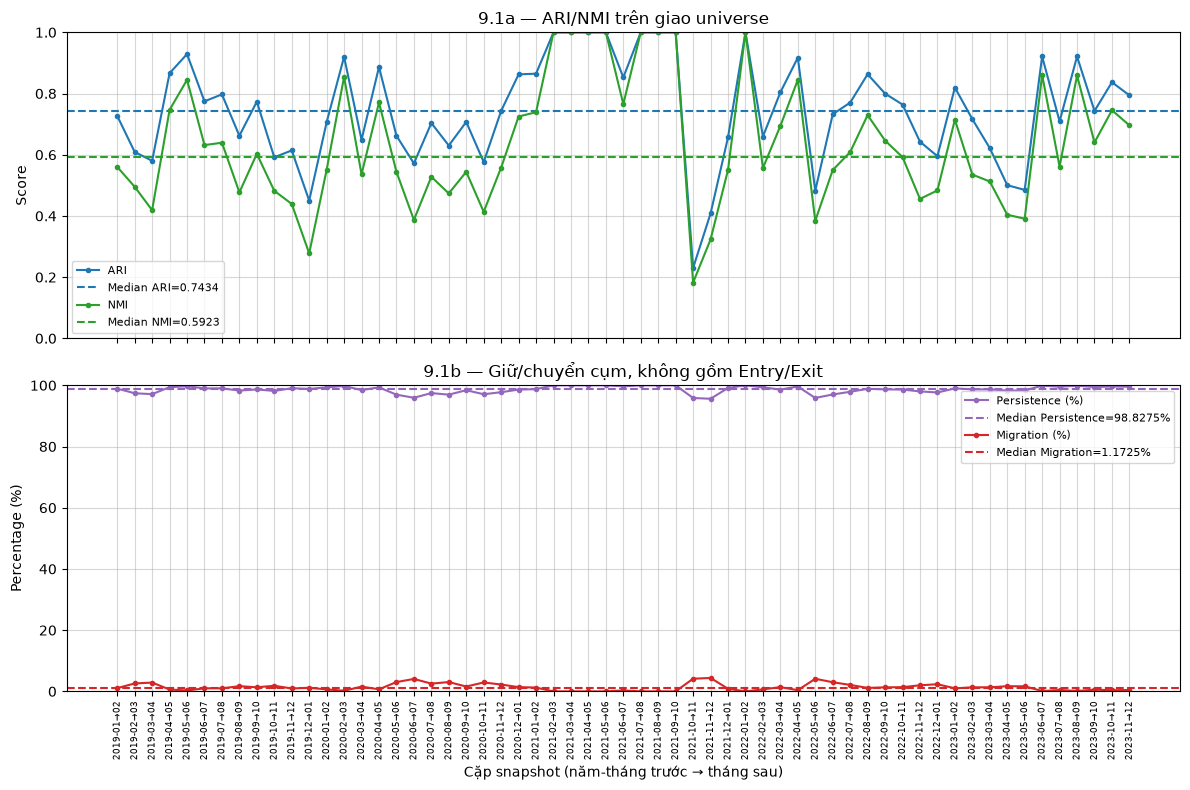

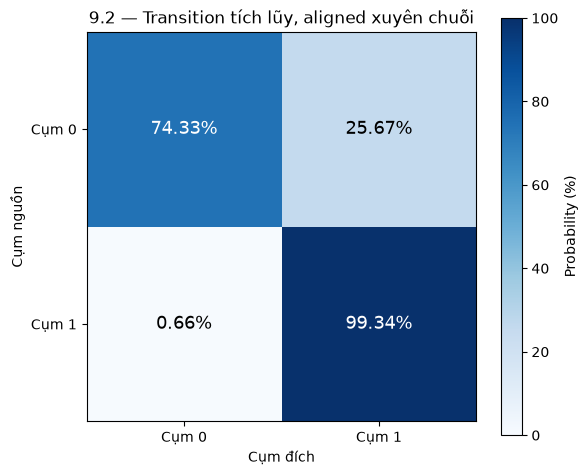

In [6]:
FIGURES = {}
x = np.arange(len(EXPECTED_PAIRS))
fig,(ax1,ax2) = plt.subplots(2,1,figsize=(12,8),sharex=True)
for metric,color in [('ari','#1f77b4'),('nmi','#2ca02c')]:
    ax1.plot(x,df_temp[metric],marker='o',markersize=3,color=color,label=metric.upper())
    ax1.axhline(df_temp[metric].median(),color=color,linestyle='--',
                label=f'Median {metric.upper()}={df_temp[metric].median():.4f}')
ax1.set(ylim=(min(0,float(df_temp.ari.min())-.03) if df_temp.ari.min()<0 else 0,1),
        ylabel='Score',title='9.1a — ARI/NMI trên giao universe')
ax1.legend(fontsize=8);ax1.grid(alpha=.5)
for metric,color,label in [
    ('persistence_probability','#9467bd','Persistence'),('migration_rate','#d62728','Migration')]:
    values = df_temp[metric]*100
    ax2.plot(x,values,marker='o',markersize=3,color=color,label=label+' (%)')
    ax2.axhline(values.median(),color=color,linestyle='--',label=f'Median {label}={values.median():.4f}%')
ax2.set(ylim=(0,100),ylabel='Percentage (%)',title='9.1b — Giữ/chuyển cụm, không gồm Entry/Exit')
labels = [f'{a[:7]}→{b[5:7]}' for a,b in EXPECTED_PAIRS]
ax2.set_xticks(x,labels,rotation=90,ha='center',fontsize=6.8)
ax2.set_xlabel('Cặp snapshot (năm-tháng trước → tháng sau)')
ax2.legend(fontsize=8);ax2.grid(alpha=.5)
fig.tight_layout()
buffer = BytesIO();fig.savefig(buffer,format='png',dpi=160,bbox_inches='tight')
FIGURES['temporal_trends.png']=buffer.getvalue()
plt.show();plt.close(fig)

fig,ax = plt.subplots(figsize=(6,5))
image = ax.imshow(transition_rates.to_numpy(),cmap='Blues',vmin=0,vmax=100)
for a in [0,1]:
    for b in [0,1]:
        value = transition_rates.loc[a,b]
        ax.text(b,a,f'{value:.2f}%',ha='center',va='center',
                color='white' if value>=55 else 'black',fontsize=13)
ax.set_xticks([0,1],['Cụm 0','Cụm 1']);ax.set_yticks([0,1],['Cụm 0','Cụm 1'])
ax.set(title='9.2 — Transition tích lũy, aligned xuyên chuỗi',xlabel='Cụm đích',ylabel='Cụm nguồn')
fig.colorbar(image,ax=ax,label='Probability (%)')
fig.tight_layout()
buffer = BytesIO();fig.savefig(buffer,format='png',dpi=160,bbox_inches='tight')
FIGURES['transition_heatmap.png']=buffer.getvalue()
plt.show();plt.close(fig)


## Bước 4 — Biện luận A/B/C theo số liệu thực tế

Persistence cao có thể bị cụm lớn chi phối; phải đọc xác suất giữ/chuyển riêng theo hàng.
Migration chỉ đo đổi nhãn trên mã chung, không tự bằng tỷ lệ mua/bán hay chi phí danh mục.
Không suy luận “chi phí thấp/an toàn” chỉ từ ngưỡng 15%; M3 còn cần weights, vốn,
Entry/Exit và mô hình thực thi. Cặp ARI thấp được ghi nhận để kiểm tra,
không gán nguyên nhân cú sốc VN-Index khi ba CSV không chứa dữ liệu chỉ số/bối cảnh đó.


In [7]:
ari,nmi = float(df_temp.ari.median()),float(df_temp.nmi.median())
persistence,migration = float(df_temp.persistence_probability.median()*100),float(df_temp.migration_rate.median()*100)
worst = df_temp.loc[df_temp.ari.idxmin()]
max_membership = df_temp.loc[universe_ratio.idxmax()]
low_ari = df_temp[df_temp.ari.lt(.50)]
low_ari_text = '; '.join(
    f'{row.from_date} → {row.to_date}: {row.ari:.6f}' for row in low_ari.itertuples(index=False)) or 'không có'
SYNTHESIS = f'''## A — Phán quyết độ ổn định

Mean/Median ARI = {df_temp.ari.mean():.6f}/{ari:.6f};
Mean/Median NMI = {df_temp.nmi.mean():.6f}/{nmi:.6f}.
ARI > 0,70 ở {int(df_temp.ari.gt(.70).sum())}/59 cặp.
ARI thấp nhất {worst.ari:.6f} tại {worst.from_date} → {worst.to_date}.
Có {len(low_ari)} cặp ARI < 0,50: {low_ari_text}.
Vì vậy độ bền phân hoạch có biến thiên đáng kể, không gọi toàn bộ chuỗi là bất biến.
Các cặp suy giảm cần được kiểm tra bối cảnh riêng; không có bằng chứng VN-Index
trong ba CSV để khẳng định nguyên nhân cú sốc thị trường hoặc dòng tiền.

Chuỗi 60 tháng liên tục, đúng 59 cặp từ {EXPECTED_PAIRS[0][0]} → {EXPECTED_PAIRS[0][1]}
đến {EXPECTED_PAIRS[-1][0]} → {EXPECTED_PAIRS[-1][1]}; không có cặp qua gap/holdout.
Drift dùng profile feature gốc cùng aligned ID, không phải khoảng cách tâm PCA;
Mean |Delta| liquidity C0/C1 = {drift_means.loc['liquidity_21',0]/1e9:.6f}/
{drift_means.loc['liquidity_21',1]/1e9:.6f} tỷ VND/phiên.
Không cộng hay xếp hạng độ lớn drift của các feature khác đơn vị.

## B — Tính bền thành viên và tác động tiềm tàng đến M3

Mean/Median Persistence = {df_temp.persistence_probability.mean()*100:.6f}%/{persistence:.6f}%;
Mean/Median Migration = {df_temp.migration_rate.mean()*100:.6f}%/{migration:.6f}%.
Theo rubric mô tả Persistence ≥80%, có {int(df_temp.persistence_probability.ge(.80).sum())}/59 cặp
độ bám nhãn cao. Tuy nhiên tích lũy theo lượt, Cụm 0 giữ {transition_rates.loc[0,0]:.4f}%,
chuyển sang Cụm 1 {transition_rates.loc[0,1]:.4f}% trên {int(denominators.loc[0])} lượt;
Cụm 1 giữ {transition_rates.loc[1,1]:.4f}%, chuyển sang Cụm 0 {transition_rates.loc[1,0]:.4f}%
trên {int(denominators.loc[1])} lượt. Persistence tổng thể cao che bớt xáo trộn
trong nhóm nhỏ; số lượt không phải số cổ phiếu duy nhất.

Tỷ lệ (Entry+Exit)/n_common cao nhất {universe_ratio.max():.4f}% tại
{max_membership.from_date} → {max_membership.to_date}. Entry/Exit là thay đổi điều kiện
tham gia universe; Migration chỉ tính mã chung. Cả hai chưa phải portfolio turnover.
Migration thấp gợi ý ít đổi nhãn trên giao universe, nhưng không bảo đảm giao dịch/thuế
hay slippage thấp. M3 phải xác định vốn, tỷ trọng, thành viên vào/ra, quy tắc tái cân bằng
và chi phí thực thi; không suy khả năng bảo toàn lợi nhuận từ thống kê nhãn.

## C — Bàn giao Nhiệm vụ 10 và giới hạn

Bằng chứng bao phủ 59/59 cặp, bốn bảng chuẩn và hai biểu đồ, đủ đầu vào so sánh
độ bền với các phương án cùng dữ liệu, universe và 60 tháng development.
Khi bàn giao phải giữ cảnh báo {len(low_ari)} cặp ARI <0,50 và xác suất chuyển của Cụm 0
{transition_rates.loc[0,1]:.4f}%; không chỉ dùng Persistence tổng thể để khẳng định ổn định.
Không tuyên bố PCA tốt hơn các phương án khác khi chưa làm đối đầu Nhiệm vụ 10.
Đây là Temporal Stability Diagnostic, không phải Dynamic Clustering;
không chọn mã, không dùng return/Sharpe/backtest và không mở holdout.
'''
SYNTHESIS += "\n\nKhi \u0111\u1ed1i chi\u1ebfu bi\u1ebfn \u0111\u1ed9ng universe \u1edf Nhi\u1ec7m v\u1ee5 10, ph\u1ea3i th\u1ed1ng nh\u1ea5t m\u1eabu s\u1ed1 t\u1eeb c\u00e1c c\u1ed9t Entry/Exit/n_common; c\u00e1c notebook legacy d\u00f9ng c\u00f4ng th\u1ee9c kh\u00e1c nhau. B\u1ed9 V2 n\u00e0y d\u00f9ng (Entry+Exit)/n_common, n\u00ean kh\u00f4ng so tr\u1ef1c ti\u1ebfp v\u1edbi t\u1ef7 l\u1ec7 d\u00f9ng m\u1eabu s\u1ed1 kh\u00e1c.\n"
display(Markdown(SYNTHESIS))


## A — Phán quyết độ ổn định

Mean/Median ARI = 0.747575/0.743427;
Mean/Median NMI = 0.636082/0.592307.
ARI > 0,70 ở 38/59 cặp.
ARI thấp nhất 0.230167 tại 2021-10-29 → 2021-11-30.
Có 5 cặp ARI < 0,50: 2019-12-31 → 2020-01-31: 0.450166; 2021-10-29 → 2021-11-30: 0.230167; 2021-11-30 → 2021-12-31: 0.408190; 2022-05-31 → 2022-06-30: 0.482463; 2023-05-31 → 2023-06-30: 0.485201.
Vì vậy độ bền phân hoạch có biến thiên đáng kể, không gọi toàn bộ chuỗi là bất biến.
Các cặp suy giảm cần được kiểm tra bối cảnh riêng; không có bằng chứng VN-Index
trong ba CSV để khẳng định nguyên nhân cú sốc thị trường hoặc dòng tiền.

Chuỗi 60 tháng liên tục, đúng 59 cặp từ 2019-01-31 → 2019-02-28
đến 2023-11-30 → 2023-12-29; không có cặp qua gap/holdout.
Drift dùng profile feature gốc cùng aligned ID, không phải khoảng cách tâm PCA;
Mean |Delta| liquidity C0/C1 = 73.555190/
1.635837 tỷ VND/phiên.
Không cộng hay xếp hạng độ lớn drift của các feature khác đơn vị.

## B — Tính bền thành viên và tác động tiềm tàng đến M3

Mean/Median Persistence = 98.640468%/98.827471%;
Mean/Median Migration = 1.359532%/1.172529%.
Theo rubric mô tả Persistence ≥80%, có 59/59 cặp
độ bám nhãn cao. Tuy nhiên tích lũy theo lượt, Cụm 0 giữ 74.3284%,
chuyển sang Cụm 1 25.6716% trên 670 lượt;
Cụm 1 giữ 99.3363%, chuyển sang Cụm 0 0.6637%
trên 26669 lượt. Persistence tổng thể cao che bớt xáo trộn
trong nhóm nhỏ; số lượt không phải số cổ phiếu duy nhất.

Tỷ lệ (Entry+Exit)/n_common cao nhất 120.2899% tại
2021-02-26 → 2021-03-31. Entry/Exit là thay đổi điều kiện
tham gia universe; Migration chỉ tính mã chung. Cả hai chưa phải portfolio turnover.
Migration thấp gợi ý ít đổi nhãn trên giao universe, nhưng không bảo đảm giao dịch/thuế
hay slippage thấp. M3 phải xác định vốn, tỷ trọng, thành viên vào/ra, quy tắc tái cân bằng
và chi phí thực thi; không suy khả năng bảo toàn lợi nhuận từ thống kê nhãn.

## C — Bàn giao Nhiệm vụ 10 và giới hạn

Bằng chứng bao phủ 59/59 cặp, bốn bảng chuẩn và hai biểu đồ, đủ đầu vào so sánh
độ bền với các phương án cùng dữ liệu, universe và 60 tháng development.
Khi bàn giao phải giữ cảnh báo 5 cặp ARI <0,50 và xác suất chuyển của Cụm 0
25.6716%; không chỉ dùng Persistence tổng thể để khẳng định ổn định.
Không tuyên bố PCA tốt hơn các phương án khác khi chưa làm đối đầu Nhiệm vụ 10.
Đây là Temporal Stability Diagnostic, không phải Dynamic Clustering;
không chọn mã, không dùng return/Sharpe/backtest và không mở holdout.


Khi đối chiếu biến động universe ở Nhiệm vụ 10, phải thống nhất mẫu số từ các cột Entry/Exit/n_common; các notebook legacy dùng công thức khác nhau. Bộ V2 này dùng (Entry+Exit)/n_common, nên không so trực tiếp với tỷ lệ dùng mẫu số khác.


## Bước 5 — Xuất kết quả chính thức

Cell tiếp theo ghi hai PNG, báo cáo Markdown và manifest/evidence Task 9.
Không thay manifest kết quả Task 6, 7 hoặc 8 và không ghi đè bộ legacy.
Chỉ khi thông báo cuối báo PASS mới xác nhận bộ kết quả Nhiệm vụ 9 đã hoàn tất.


In [ ]:
assert sha(SOURCE_MANIFEST_PATH)==SOURCE_MANIFEST_HASH
for relative,expected in EXPECTED_SOURCE_HASHES.items():
    assert sha(TASK_DIR/relative)==expected
for name,expected in input_hashes.items():
    assert sha(EVAL_DIR/name)==expected
for name,content in FIGURES.items():
    immutable_bytes(EVAL_DIR/name,content)
report = (
    '# Báo cáo Nhiệm vụ 9 — Temporal Stability PCA + K-Means V2\n\n'
    + 'Nguồn: ba CSV phẳng trong m2-evaluation-pca-kmeans-v2, chuẩn hóa từ Task 6 V2. '
    + 'ARI/NMI không được tính lại; nhãn aligned giữ nguyên; không fit model.\n\n'
    + '\n\n'.join(f'## Bảng {i}\n\n'+markdown_table(frame.round(6))
                  for i,frame in enumerate([table1,table2,table3,table4],1))
    + '\n\n![Temporal trends](../artifacts/m2-evaluation-pca-kmeans-v2/temporal_trends.png)\n\n'
    + '![Transition heatmap](../artifacts/m2-evaluation-pca-kmeans-v2/transition_heatmap.png)\n\n'
    + SYNTHESIS
)
# Preserve the curated full report after verifying its recorded checksum.
if REPORT_PATH.exists() and '<!-- PCA_KMEANS_V2_FULL_REPORT -->' in REPORT_PATH.read_text(encoding='utf-8'):
    saved_report_manifest = json.loads((EVAL_DIR / 'task9_manifest.json').read_text(encoding='utf-8'))
    assert sha(REPORT_PATH) == saved_report_manifest['report'][REPORT_PATH.relative_to(ROOT).as_posix()]
else:
    immutable_bytes(REPORT_PATH,report.encode('utf-8'))
evidence = dict(
    tables={f'table{i}':frame.to_dict('records') for i,frame in enumerate([table1,table2,table3,table4],1)},
    expected_pairs=EXPECTED_PAIRS,universe_ratio_formula='100 * (entered_count + exited_count) / n_common',
    transition_rate_basis='pooled counts / pooled source-cluster counts; common securities only',
    low_ari_pairs=low_ari.to_dict('records'),ari_below_050_count=len(low_ari),
    development_gap_count=0,drift_units='liquidity in VND in CSV; billion VND in table; other original units',
)
evidence_path=EVAL_DIR/'task9_temporal_evidence.json'
immutable_bytes(evidence_path,json_bytes(evidence))
artifact_paths=[
    *[EVAL_DIR/name for name in input_hashes],EVAL_DIR/'task9_inputs_manifest.json',
    *[EVAL_DIR/name for name in FIGURES],evidence_path]
output_manifest=dict(
    artifact_id='m2-task9-pca-kmeans-temporal-v2',status='complete',
    source_artifact_id=source_manifest['artifact_id'],source_manifest_sha256=SOURCE_MANIFEST_HASH,
    source_artifacts_sha256=EXPECTED_SOURCE_HASHES,n_snapshots=60,n_pairs=59,k=2,
    no_refit=True,ari_nmi_recomputed=False,holdout_accessed=False,development_gap_count=0,
    table_shapes=[[4,6],[4,5],[8,3],[59,5]],
    artifacts={p.relative_to(EVAL_DIR).as_posix():sha(p) for p in artifact_paths},
    report={REPORT_PATH.relative_to(ROOT).as_posix():sha(REPORT_PATH)},
)
for relative,expected in output_manifest['artifacts'].items():
    assert sha(EVAL_DIR/relative)==expected
immutable_bytes(EVAL_DIR/'task9_manifest.json',json_bytes(output_manifest))
print('PASS nhiệm vụ 9 — PCA + K-Means V2:',EVAL_DIR/'task9_manifest.json')
print('Báo cáo:',REPORT_PATH)


## A — Phán quyết độ ổn định

Mean/Median ARI = 0.747575/0.743427;
Mean/Median NMI = 0.636082/0.592307.
ARI > 0,70 ở 38/59 cặp.
ARI thấp nhất 0.230167 tại 2021-10-29 → 2021-11-30.
Có 5 cặp ARI < 0,50: 2019-12-31 → 2020-01-31: 0.450166; 2021-10-29 → 2021-11-30: 0.230167; 2021-11-30 → 2021-12-31: 0.408190; 2022-05-31 → 2022-06-30: 0.482463; 2023-05-31 → 2023-06-30: 0.485201.
Vì vậy độ bền phân hoạch có biến thiên đáng kể, không gọi toàn bộ chuỗi là bất biến.
Các cặp suy giảm cần được kiểm tra bối cảnh riêng; không có bằng chứng VN-Index
trong ba CSV để khẳng định nguyên nhân cú sốc thị trường hoặc dòng tiền.

Chuỗi 60 tháng liên tục, đúng 59 cặp từ 2019-01-31 → 2019-02-28
đến 2023-11-30 → 2023-12-29; không có cặp qua gap/holdout.
Drift dùng profile feature gốc cùng aligned ID, không phải khoảng cách tâm PCA;
Mean |Delta| liquidity C0/C1 = 73.555190/
1.635837 tỷ VND/phiên.
Không cộng hay xếp hạng độ lớn drift của các feature khác đơn vị.

## B — Tính bền thành viên và tác động tiềm tàng đến M3

Mean/Median Persistence = 98.640468%/98.827471%;
Mean/Median Migration = 1.359532%/1.172529%.
Theo rubric mô tả Persistence ≥80%, có 59/59 cặp
độ bám nhãn cao. Tuy nhiên tích lũy theo lượt, Cụm 0 giữ 74.3284%,
chuyển sang Cụm 1 25.6716% trên 670 lượt;
Cụm 1 giữ 99.3363%, chuyển sang Cụm 0 0.6637%
trên 26669 lượt. Persistence tổng thể cao che bớt xáo trộn
trong nhóm nhỏ; số lượt không phải số cổ phiếu duy nhất.

Tỷ lệ (Entry+Exit)/n_common cao nhất 120.2899% tại
2021-02-26 → 2021-03-31. Entry/Exit là thay đổi điều kiện
tham gia universe; Migration chỉ tính mã chung. Cả hai chưa phải portfolio turnover.
Migration thấp gợi ý ít đổi nhãn trên giao universe, nhưng không bảo đảm giao dịch/thuế
hay slippage thấp. M3 phải xác định vốn, tỷ trọng, thành viên vào/ra, quy tắc tái cân bằng
và chi phí thực thi; không suy khả năng bảo toàn lợi nhuận từ thống kê nhãn.

## C — Bàn giao Nhiệm vụ 10 và giới hạn

Bằng chứng bao phủ 59/59 cặp, bốn bảng chuẩn và hai biểu đồ, đủ đầu vào so sánh
độ bền với các phương án cùng dữ liệu, universe và 60 tháng development.
Khi bàn giao phải giữ cảnh báo 5 cặp ARI <0,50 và xác suất chuyển của Cụm 0
25.6716%; không chỉ dùng Persistence tổng thể để khẳng định ổn định.
Không tuyên bố PCA tốt hơn các phương án khác khi chưa làm đối đầu Nhiệm vụ 10.
Đây là Temporal Stability Diagnostic, không phải Dynamic Clustering;
không chọn mã, không dùng return/Sharpe/backtest và không mở holdout.


Khi đối chiếu biến động universe ở Nhiệm vụ 10, phải thống nhất mẫu số từ các cột Entry/Exit/n_common; các notebook legacy dùng công thức khác nhau. Bộ V2 này dùng (Entry+Exit)/n_common, nên không so trực tiếp với tỷ lệ dùng mẫu số khác.

